# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional
expression notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the
ends of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that
pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the
mesenchymal/neural-crest FOXC and PRRX factors** — along *this* trajectory and let the data
choose the most end-specific factor at each end, gating out factors below a detection floor
(the Kürten lesson: SNAI1/ZEB1 sit near the 10x dropout floor and must not be overlaid blind).
We then test whether the EMT-TF axis is genuinely **bipolar** (a root-specific factor opposite
a terminus-specific one, as in Puram) or **monotone** (all factors rise toward one end); the
figure adapts to whichever the data show, rather than fabricating a split. Deliverable:
`expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 2337 | pseudotime range 0.0 -> 17.35


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF we record the fraction of cells expressing it, its mean expression in
the early (root) vs late (terminus) pseudotime tercile, and its Spearman correlation with
pseudotime. Among factors above a 3% expression floor, the most negatively-correlated marks
the root end and the most positively-correlated marks the terminus. Factors below the floor
are too sparse to overlay honestly.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print('detection floor (3%) applied so near-dropout factors are not overlaid blind (Kürten lesson).')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
TWIST2      0.032       0.004      0.017     0.052 LATE(terminus)
 FOXC2      0.001       0.000      0.000     0.053 LATE(terminus)
 FOXC1      0.044       0.004      0.014     0.103 LATE(terminus)
 PRRX2      0.033       0.001      0.046     0.183 LATE(terminus)
 PRRX1      0.247       0.049      0.403     0.210 LATE(terminus)
  ZEB2      0.251       0.023      0.058     0.210 LATE(terminus)
TWIST1      0.247       0.191      0.681     0.224 LATE(terminus)
 SNAI1      0.159       0.013      0.157     0.265 LATE(terminus)
 SNAI2      0.417       0.064      0.375     0.275 LATE(terminus)
  ZEB1      0.527       0.073      0.469     0.393 LATE(terminus)

derived pair: TWIST2 (early/root) <-> ZEB1 (late/terminus)
detection floor (3%) applied so near-dropout factors are not overlaid blind (Kürten lesson).


### Is the EMT-TF axis bipolar or monotone? (data-driven figure choice)
Puram/Kürten's overlay assumes a **bipolar** axis — a root-specific EMT-TF opposite a
terminus-specific one. That is only honest if a genuinely root-enriched factor exists. Here
we test it: a bipolar overlay is drawn **only if** the derived early factor is (i) expressed
above the 3% floor and (ii) actually root-shifted (its upper-quartile expressers sit in the
early pseudotime half, giving a real early↔late separation ≥0.15). Otherwise the axis is
**monotone** — every EMT-TF rises toward one end — and the honest figure is a graded
expression overlay of the single most end-specific factor, not a fabricated two-colour split.

In [5]:
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
# test whether the derived early factor is genuinely root-shifted
ve = _vec(early_tf); pe = ve[ve>0]
sel_e = ve > (np.quantile(pe,0.75) if pe.size else np.inf)
early_pt = tn[sel_e].mean() if sel_e.any() else np.nan
vl = _vec(late_tf); pl_ = vl[vl>0]
sel_l = vl > (np.quantile(pl_,0.75) if pl_.size else np.inf)
sep = abs(tn[sel_l].mean() - early_pt)
bipolar = (df.set_index('TF').loc[early_tf,'frac_expr'] > 0.03) and (early_pt < 0.5) and (sep >= 0.15)
print(f'{early_tf} upper-quartile expressers mean pseudotime = {early_pt:.2f}; '
      f'early<->late separation = {sep:.2f} -> axis is {"BIPOLAR" if bipolar else "MONOTONE"}')
if not bipolar:
    print(f'No root-specific EMT-TF: all candidates rise toward the terminus. '
          f'Strongest terminus factor = {late_tf} '
          f'({(vl>0).mean()*100:.0f}% expressing, rho_vs_t={df.set_index("TF").loc[late_tf,"rho_vs_t"]:+.2f}).')

TWIST2 upper-quartile expressers mean pseudotime = 0.68; early<->late separation = 0.12 -> axis is MONOTONE
No root-specific EMT-TF: all candidates rise toward the terminus. Strongest terminus factor = ZEB1 (53% expressing, rho_vs_t=+0.39).


ZEB1: 52.7% expressing, mean pseudotime of upper-quartile expressers = 0.79 (all cells = 0.46)
EMT axis is monotone (rises to the mesenchymal/neural-crest terminus)
saved expression.pdf


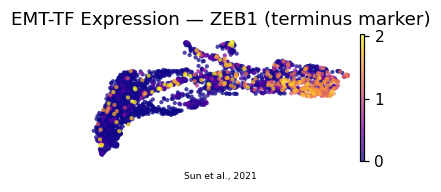

In [6]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
if bipolar:
    thr = {g: float(np.quantile(_vec(g)[_vec(g)>0],0.75)) for g in [early_tf, late_tf]}
    sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
    order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
    colors = {early_tf:'tab:blue', late_tf:'tab:red'}
    sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
    for g in order:
        sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=30, alpha=.8,
                   frameon=False, show=False, ax=ax)
    ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
else:
    # monotone axis: graded expression of the single strongest terminus EMT-TF
    sc.pl.umap(adata, color=late_tf, cmap='plasma', size=30, alpha=.75, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=f'EMT-TF Expression — {late_tf} (terminus marker)')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.14,'Sun et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print(f'{late_tf}: {(_vec(late_tf)>0).mean()*100:.1f}% expressing, '
      f'mean pseudotime of upper-quartile expressers = {tn[sel_l].mean():.2f} (all cells = {tn.mean():.2f})')
print('EMT axis is', 'bipolar' if bipolar else 'monotone (rises to the mesenchymal/neural-crest terminus)')
print('saved expression.pdf')